<a href="https://colab.research.google.com/github/YSSFM/African_Wildlife_Detection_and_Counting_Project/blob/main/entrainement_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 65.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [2]:
import torch, ultralytics
print("GPU :", torch.cuda.is_available())
print("Ultralytics:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU : True
Ultralytics: 8.4.216


In [3]:
from ultralytics import YOLO
model = YOLO('yolov8n.pt')

In [4]:
results = model.train(
    data='african-wildlife.yaml',
    imgsz=512,
    epochs=15,
    seed=42,
    scale=0.2,
    translate=0.05,
    project='runs',
    name='modele_B'
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=african-wildlife.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=modele_B, nbs=64, nms=None, opset=None, optimize=False, optimizer=a

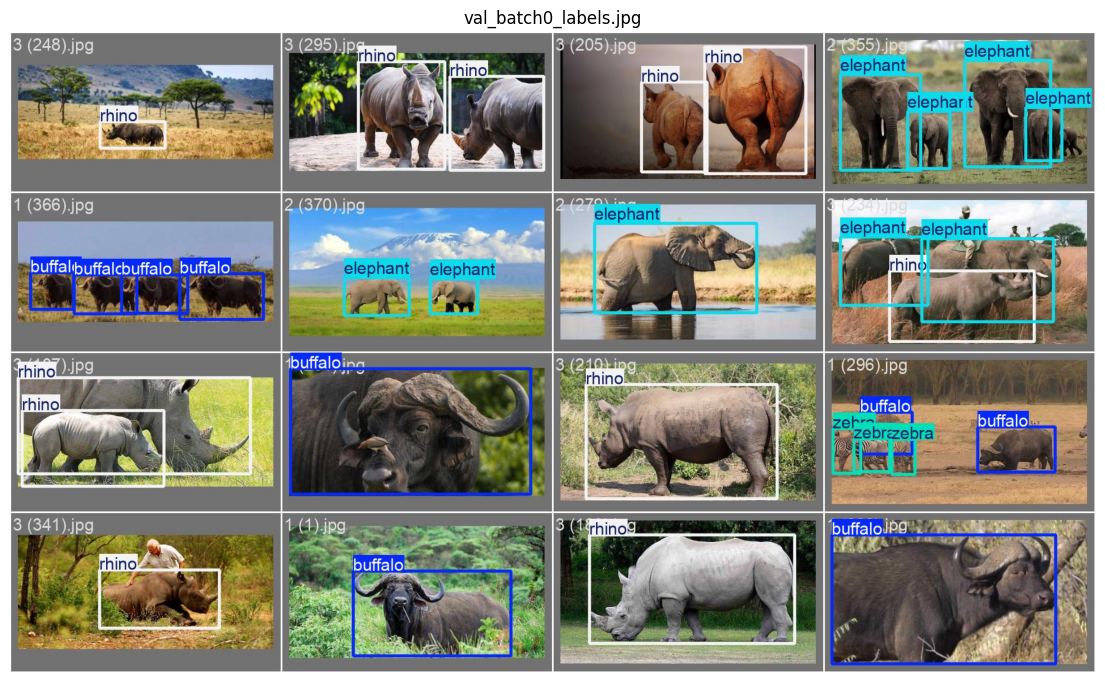

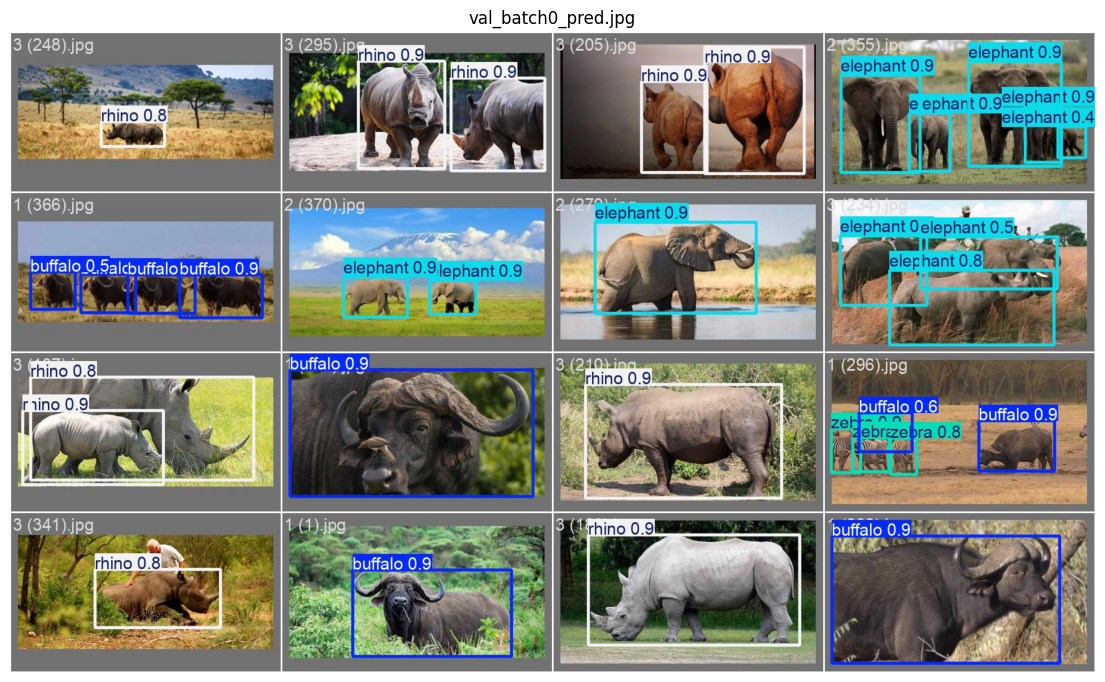

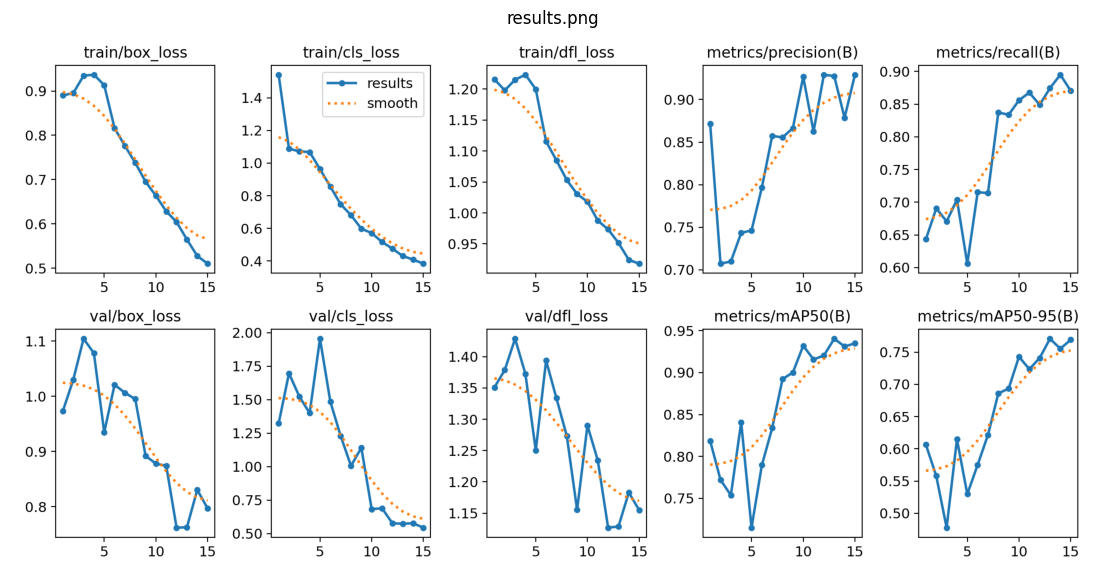

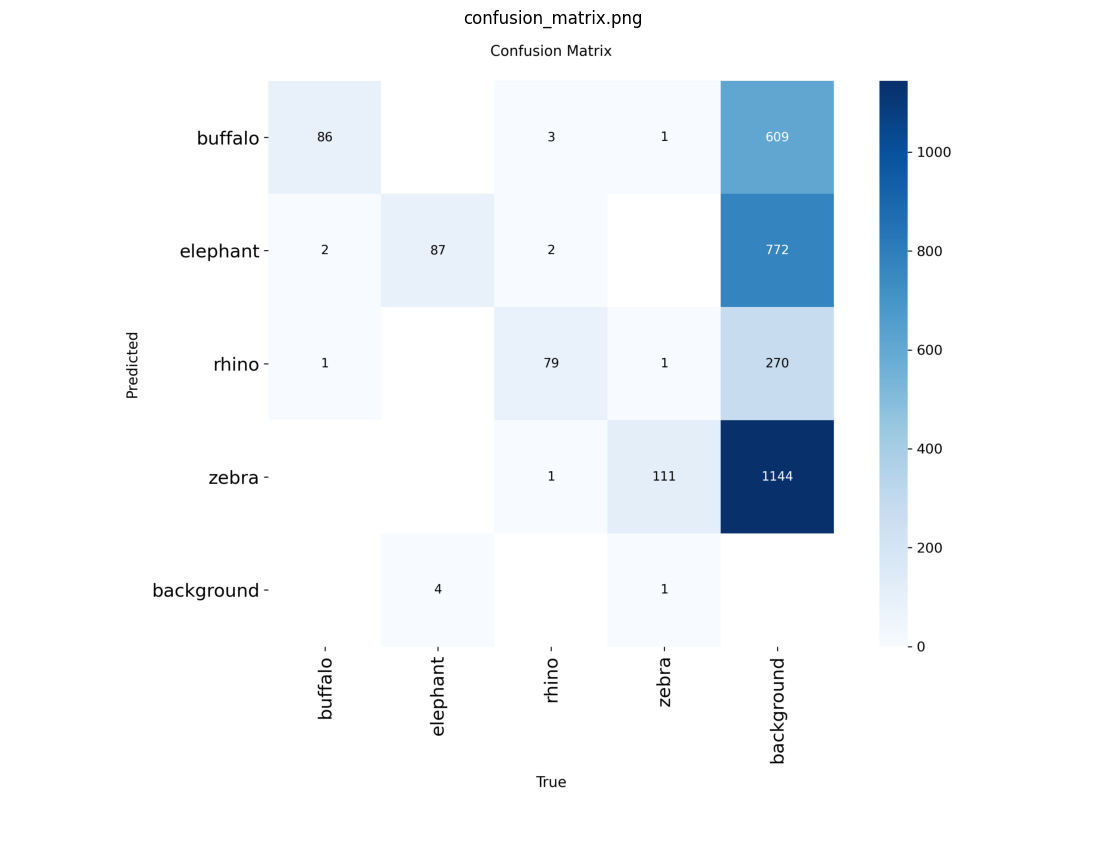

In [5]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg, os

d = results.save_dir
for f in ["val_batch0_labels.jpg", "val_batch0_pred.jpg",
          "results.png", "confusion_matrix.png"]:
    p = os.path.join(d, f)
    if os.path.exists(p):
        plt.figure(figsize=(14, 14))
        plt.imshow(mpimg.imread(p))
        plt.axis("off")
        plt.title(f)
        plt.show()

In [6]:
from ultralytics import YOLO
m = YOLO(f"{results.save_dir}/weights/best.pt")
preds = m.predict("/content/datasets/african-wildlife/images/val",
                  imgsz=512, conf=0.25, save=True, max_det=50)


image 1/225 /content/datasets/african-wildlife/images/val/1 (1).jpg: 288x512 1 buffalo, 5.6ms
image 2/225 /content/datasets/african-wildlife/images/val/1 (102).jpg: 384x512 1 buffalo, 20.3ms
image 3/225 /content/datasets/african-wildlife/images/val/1 (111).jpg: 384x512 1 buffalo, 7.1ms
image 4/225 /content/datasets/african-wildlife/images/val/1 (120).jpg: 352x512 1 buffalo, 18.7ms
image 5/225 /content/datasets/african-wildlife/images/val/1 (122).jpg: 352x512 1 buffalo, 7.9ms
image 6/225 /content/datasets/african-wildlife/images/val/1 (127).jpg: 352x512 1 buffalo, 10.1ms
image 7/225 /content/datasets/african-wildlife/images/val/1 (136).jpg: 352x512 1 buffalo, 6.2ms
image 8/225 /content/datasets/african-wildlife/images/val/1 (138).jpg: 352x512 1 buffalo, 6.4ms
image 9/225 /content/datasets/african-wildlife/images/val/1 (145).jpg: 352x512 1 buffalo, 6.8ms
image 10/225 /content/datasets/african-wildlife/images/val/1 (149).jpg: 384x512 1 buffalo, 8.7ms
image 11/225 /content/datasets/africa

Images sauvegardées dans : /content/runs/detect/predict


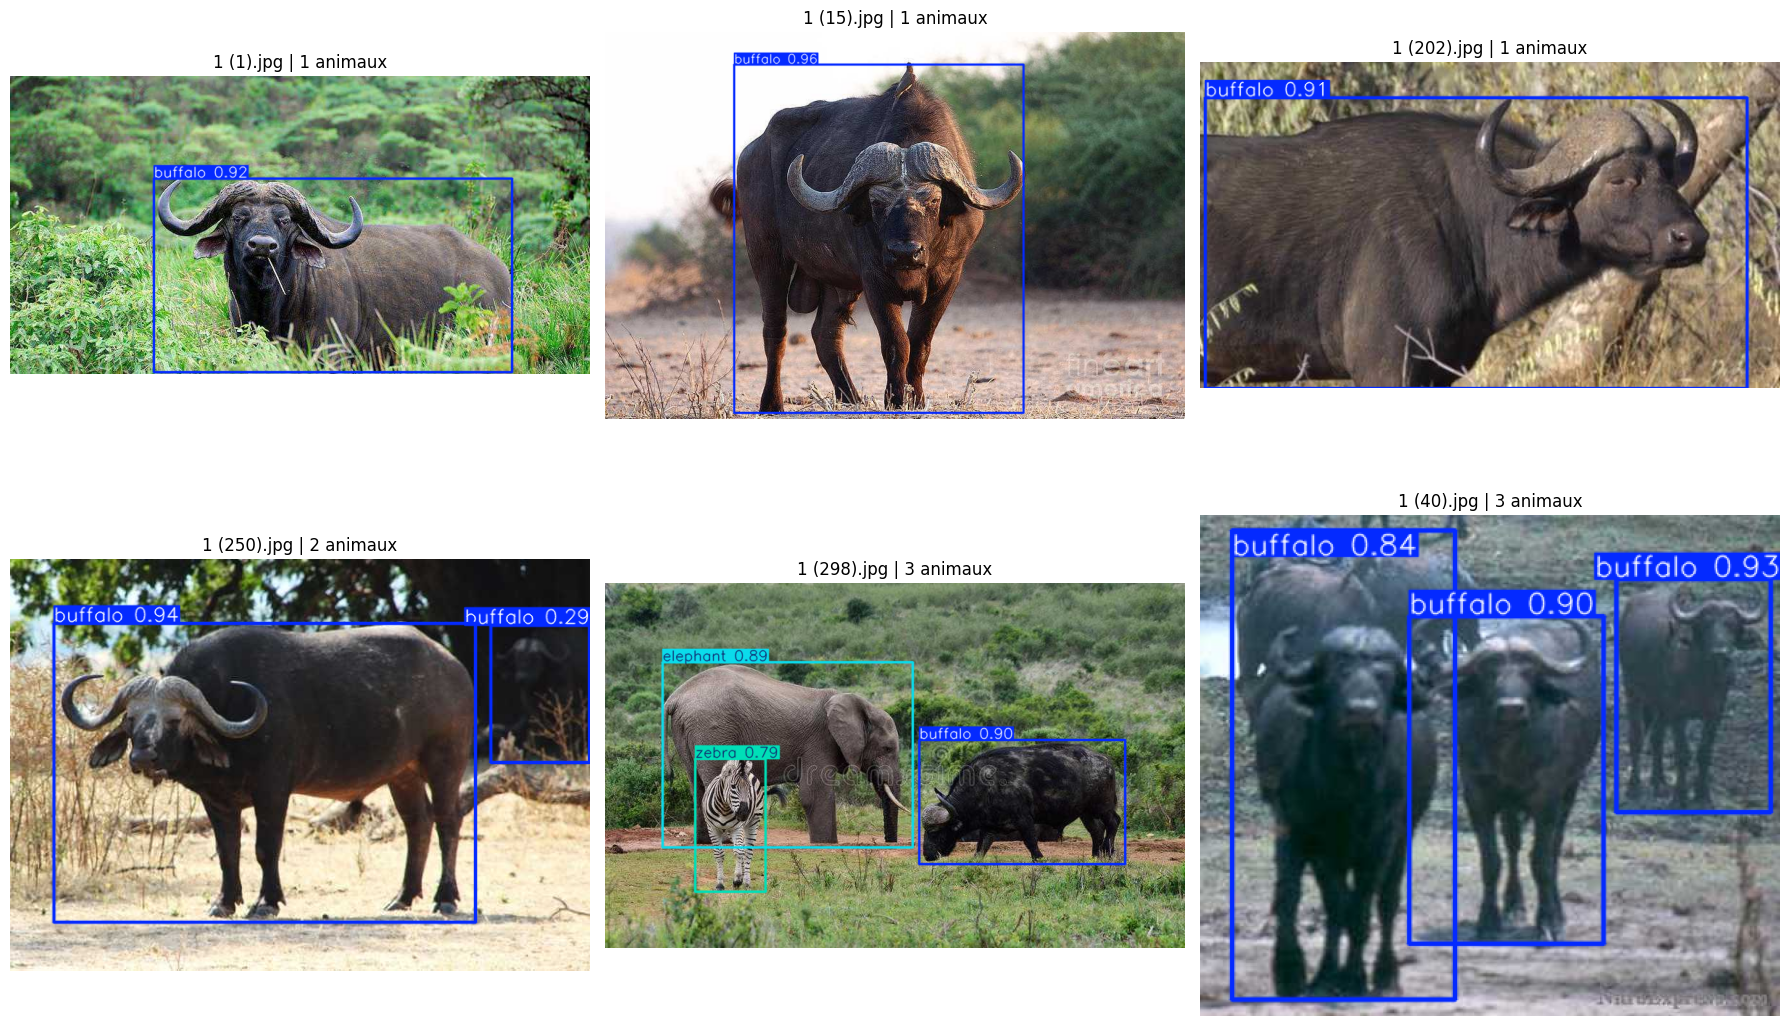

In [7]:
import matplotlib.pyplot as plt

print("Images sauvegardées dans :", preds[0].save_dir)

idx = [0, 10, 20, 30, 40, 50]   # change ces numéros pour voir d'autres images
plt.figure(figsize=(18, 12))
for k, i in enumerate(idx):
    plt.subplot(2, 3, k + 1)
    plt.imshow(preds[i].plot()[..., ::-1])   # [..., ::-1] corrige les couleurs
    plt.title(f"{preds[i].path.split('/')[-1]} | {len(preds[i].boxes)} animaux")
    plt.axis("off")
plt.tight_layout()
plt.show()

Animaux manqués          : 28
Mauvaise classe          : 10
Boîtes en trop (fausses) : 39
52 images avec au moins une erreur sur 225


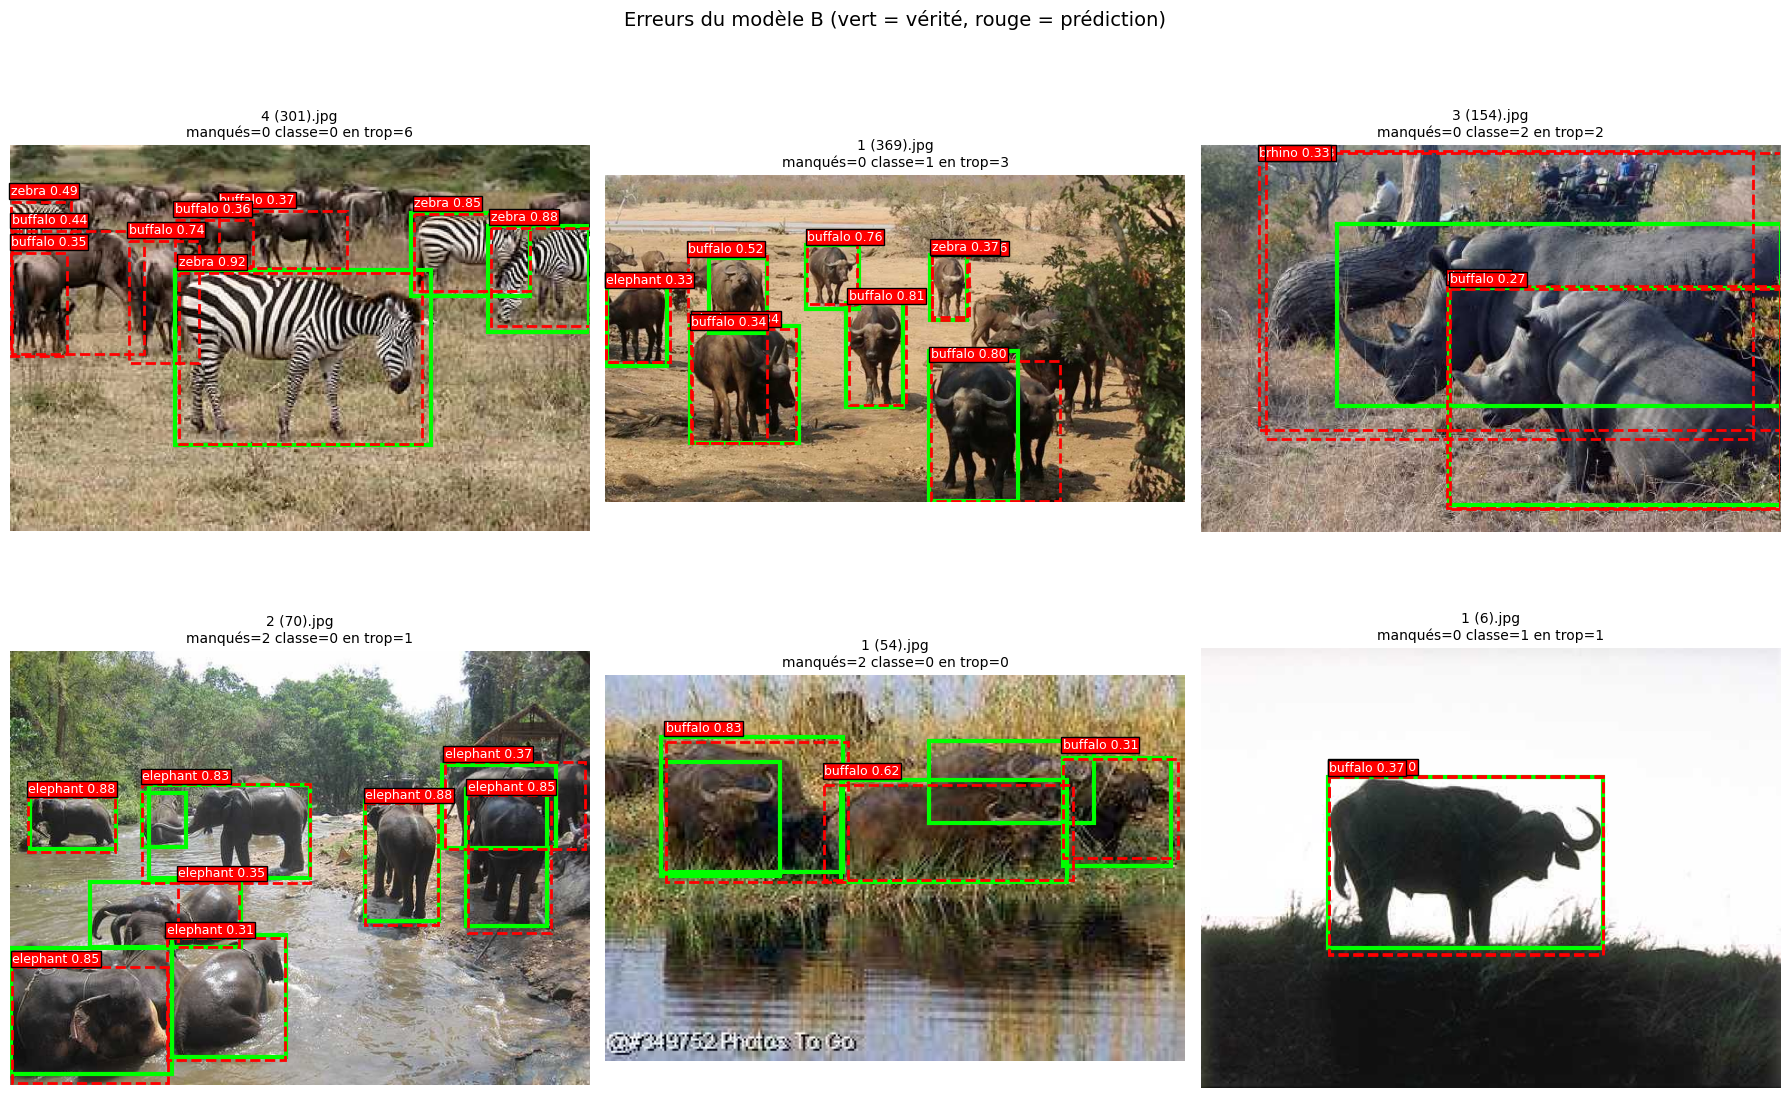

In [9]:
import os, numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

LBL = "/content/datasets/african-wildlife/labels/val"
names = m.names

def load_gt(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    g = []
    for line in open(f"{LBL}/{stem}.txt"):
        p = line.split()
        if len(p) >= 5:
            c, xc, yc, w, h = int(p[0]), *map(float, p[1:5])
            g.append((c, xc-w/2, yc-h/2, xc+w/2, yc+h/2))
    return g

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    ua = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter/ua if ua > 0 else 0

def analyse(r):
    gt = load_gt(r.path)
    pb = r.boxes.xyxyn.cpu().numpy()
    pc = r.boxes.cls.cpu().numpy().astype(int)
    used, miss, wrong = set(), [], []
    for g in gt:
        best, bi = 0, None
        for j in range(len(pb)):
            if j in used: continue
            v = iou(g[1:], pb[j])
            if v > best: best, bi = v, j
        if bi is not None and best >= 0.5:
            used.add(bi)
            if pc[bi] != g[0]: wrong.append((g[0], pc[bi]))
        else:
            miss.append(g[0])
    extra = [pc[j] for j in range(len(pb)) if j not in used]
    return gt, miss, wrong, extra

res = [(r, *analyse(r)) for r in preds]
print("Animaux manqués          :", sum(len(x[2]) for x in res))
print("Mauvaise classe          :", sum(len(x[3]) for x in res))
print("Boîtes en trop (fausses) :", sum(len(x[4]) for x in res))

def show(items, titre):
    n = len(items)
    plt.figure(figsize=(18, 6 * ((n + 2) // 3)))
    for k, (r, gt, miss, wrong, extra) in enumerate(items):
        ax = plt.subplot((n + 2) // 3, 3, k + 1)
        ax.imshow(r.orig_img[..., ::-1])
        H, W = r.orig_shape
        for c, x1, y1, x2, y2 in gt:
            ax.add_patch(Rectangle((x1*W, y1*H), (x2-x1)*W, (y2-y1)*H,
                         fill=False, edgecolor="lime", lw=3))
        for b, c, s in zip(r.boxes.xyxyn.cpu().numpy(),
                           r.boxes.cls.cpu().numpy().astype(int),
                           r.boxes.conf.cpu().numpy()):
            ax.add_patch(Rectangle((b[0]*W, b[1]*H), (b[2]-b[0])*W, (b[3]-b[1])*H,
                         fill=False, edgecolor="red", lw=2, ls="--"))
            ax.text(b[0]*W, max(b[1]*H-5, 10), f"{names[c]} {s:.2f}",
                    color="white", fontsize=9, bbox=dict(facecolor="red", pad=1))
        ax.set_title(f"{os.path.basename(r.path)}\nmanqués={len(miss)} classe={len(wrong)} en trop={len(extra)}",
                     fontsize=10)
        ax.axis("off")
    plt.suptitle(titre, fontsize=14)
    plt.tight_layout()
    plt.savefig("/content/erreurs_B.png", dpi=150, bbox_inches="tight")
    plt.show()

# images avec erreurs, les plus mauvaises d'abord
err = [x for x in res if x[2] or x[3] or x[4]]
err.sort(key=lambda x: -(len(x[2]) + len(x[3]) + len(x[4])))
print(len(err), "images avec au moins une erreur sur", len(res))
show(err[:6], "Erreurs du modèle B (vert = vérité, rouge = prédiction)")

In [10]:
import shutil, os, glob, json, ultralytics
from google.colab import drive
drive.mount('/content/drive')

src  = str(results.save_dir)                  # runs/.../modele_B
pred = str(preds[0].save_dir)                 # images prédites
base = '/content/drive/MyDrive/Projet_CNN'
poids, res = f'{base}/poids', f'{base}/resultats/modele_B'
for d in (poids, res, f'{res}/predictions_val'):
    os.makedirs(d, exist_ok=True)

# 1. Poids (Drive seulement, jamais GitHub)
shutil.copy(f'{src}/weights/best.pt', f'{poids}/modele_B_best.pt')
shutil.copy(f'{src}/weights/last.pt', f'{poids}/modele_B_last.pt')

# 2. Courbes, métriques, matrices, exemples de validation
for f in ['results.csv', 'results.png', 'args.yaml',
          'confusion_matrix.png', 'confusion_matrix_normalized.png',
          'BoxPR_curve.png', 'BoxF1_curve.png', 'labels.jpg']:
    if os.path.exists(f'{src}/{f}'):
        shutil.copy(f'{src}/{f}', res)
for f in glob.glob(f'{src}/val_batch*.jpg'):
    shutil.copy(f, res)

# 3. Prédictions sur la validation + figure des erreurs
shutil.copytree(pred, f'{res}/predictions_val', dirs_exist_ok=True)
if os.path.exists('/content/erreurs_B.png'):
    shutil.copy('/content/erreurs_B.png', res)

# 4. Fiche récapitulative pour le rapport
info = {"modele": "yolov8n", "seed": 42, "imgsz": 512, "epochs": 15,
        "scale": 0.2, "translate": 0.05,
        "ultralytics": ultralytics.__version__,
        "duree_heures": 0.061, "conf_predictions": 0.25}
try:
    info["metriques_val"] = {k: round(float(v), 4)
                             for k, v in results.results_dict.items()}
except Exception:
    pass
json.dump(info, open(f'{res}/fiche_modele_B.json', 'w'), indent=2)

print("✅ Tout est sur le Drive :", base)
!ls -R "{base}" | head -60

Mounted at /content/drive
✅ Tout est sur le Drive : /content/drive/MyDrive/Projet_CNN
/content/drive/MyDrive/Projet_CNN:
poids
resultats

/content/drive/MyDrive/Projet_CNN/poids:
modele_B_best.pt
modele_B_last.pt

/content/drive/MyDrive/Projet_CNN/resultats:
modele_B
modele_B_results.csv
modele_B_results.png

/content/drive/MyDrive/Projet_CNN/resultats/modele_B:
args.yaml
BoxF1_curve.png
BoxPR_curve.png
confusion_matrix_normalized.png
confusion_matrix.png
erreurs_B.png
fiche_modele_B.json
labels.jpg
predictions_val
results.csv
results.png
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg

/content/drive/MyDrive/Projet_CNN/resultats/modele_B/predictions_val:
1 (102).jpg
1 (111).jpg
1 (120).jpg
1 (122).jpg
1 (127).jpg
1 (136).jpg
1 (138).jpg
1 (145).jpg
1 (149).jpg
1 (159).jpg
1 (15).jpg
1 (162).jpg
1 (170).jpg
1 (174).jpg
1 (177).jpg
1 (17).jpg
1 (191).jpg
1 (194).jpg
1 (1).jpg
1 (200).jpg
1 (202).jpg
1 (203).jp